# Activity 8.01 — Cities
CISC7204 | mc652817

Python 3 inline fix: render() uses geoplotlib.savefig() + IPython.display.Image, not geoplotlib.inline(). Static figures appear below cells. Required hover, animation and key events retain show() windows. Close interactive windows to continue.
Real data, OpenGL rendering and online tile access have not been tested here. Run locally and save genuine outputs/screenshots before submission. No site-packages changes.


In [16]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import geoplotlib
from geoplotlib.utils import DataAccessObject, BoundingBox

def find_data(name):
    for folder in ('.','..','Datasets','../Datasets','../../Datasets','../../../Datasets','../../../../Datasets'):
        p=Path(folder)/name
        if p.is_file(): return p.resolve()
    raise FileNotFoundError(f'Place {name} beside this notebook or in the root Datasets folder.')

def clean(frame):
    frame=frame.copy()
    for col in ('lat','lon'): frame[col]=pd.to_numeric(frame[col],errors='coerce')
    valid=np.isfinite(frame['lat']) & np.isfinite(frame['lon']) & frame['lat'].between(-90,90) & frame['lon'].between(-180,180)
    print('Invalid coordinates removed:',int((~valid).sum()))
    frame=frame.loc[valid].reset_index(drop=True)
    if frame.empty: raise ValueError('No valid coordinates.')
    return frame

PROVIDERS={
 'positron':{'url':lambda z,x,y:f'https://a.basemaps.cartocdn.com/light_all/{z}/{x}/{y}.png','tiles_dir':'carto_positron_https','attribution':'© OpenStreetMap contributors © CARTO'},
 'darkmatter':{'url':lambda z,x,y:f'https://a.basemaps.cartocdn.com/dark_all/{z}/{x}/{y}.png','tiles_dir':'carto_darkmatter_https','attribution':'© OpenStreetMap contributors © CARTO'},
 'hot':{'url':lambda z,x,y:f'https://a.tile.openstreetmap.fr/hot/{z}/{x}/{y}.png','tiles_dir':'osm_hot_https','attribution':'© OpenStreetMap contributors; HOT style; OpenStreetMap France'}
}
def new_map(provider="hot", bbox=None):
    geoplotlib.clear()

    if provider not in PROVIDERS:
        raise ValueError(f"Unknown provider: {provider}")

    geoplotlib.tiles_provider(PROVIDERS[provider])

    geoplotlib.set_bbox(
        bbox if bbox is not None else BoundingBox.WORLD
    )

def render(interactive=False, width=900):
    if interactive:
        print('Close the map window to let the notebook continue.')
        geoplotlib.show()
        return

    from tempfile import TemporaryDirectory
    from IPython.display import Image, display

    # Avoid geoplotlib.inline()'s legacy Python 2 base64 encoding.
    with TemporaryDirectory(prefix='geoplotlib_') as temp_dir:
        image_base = Path(temp_dir) / 'map'
        geoplotlib.savefig(str(image_base))
        candidates = [Path(str(image_base) + '.png'), image_base]
        image_path = next((p for p in candidates
                           if p.is_file() and p.stat().st_size > 0), None)
        if image_path is None:
            raise RuntimeError(
                'Geoplotlib did not create a map image. Check the preceding '
                'output for rendering, OpenGL, or tile-download errors.'
            )
        display(Image(data=image_path.read_bytes(), format='png', width=width))


## Load and types

In [17]:
df=pd.read_csv(find_data('world_cities_pop.csv'),low_memory=False)
display(df.head()); display(df.dtypes)
df['lat']=df['Latitude']; df['lon']=df['Longitude']
df['Population']=pd.to_numeric(df['Population'],errors='coerce')
df['Country']=df['Country'].astype('string').str.strip().str.lower()
df['City']=df['City'].fillna('').astype(str).str.strip()
df=clean(df)


,Country,City,AccentCity,Region,Population,Latitude,Longitude
0,ad,aixas,Aixàs,06,NaN,42.483333,1.466667
1,ad,aixirivali,Aixirivali,06,NaN,42.466667,1.500000
2,ad,aixirivall,Aixirivall,06,NaN,42.466667,1.500000
3,ad,aixirvall,Aixirvall,06,NaN,42.466667,1.500000
4,ad,aixovall,Aixovall,06,NaN,42.466667,1.483333


Country        object
City           object
AccentCity     object
Region         object
Population    float64
Latitude      float64
Longitude     float64
dtype: object

Invalid coordinates removed: 0


## All cities dot plot

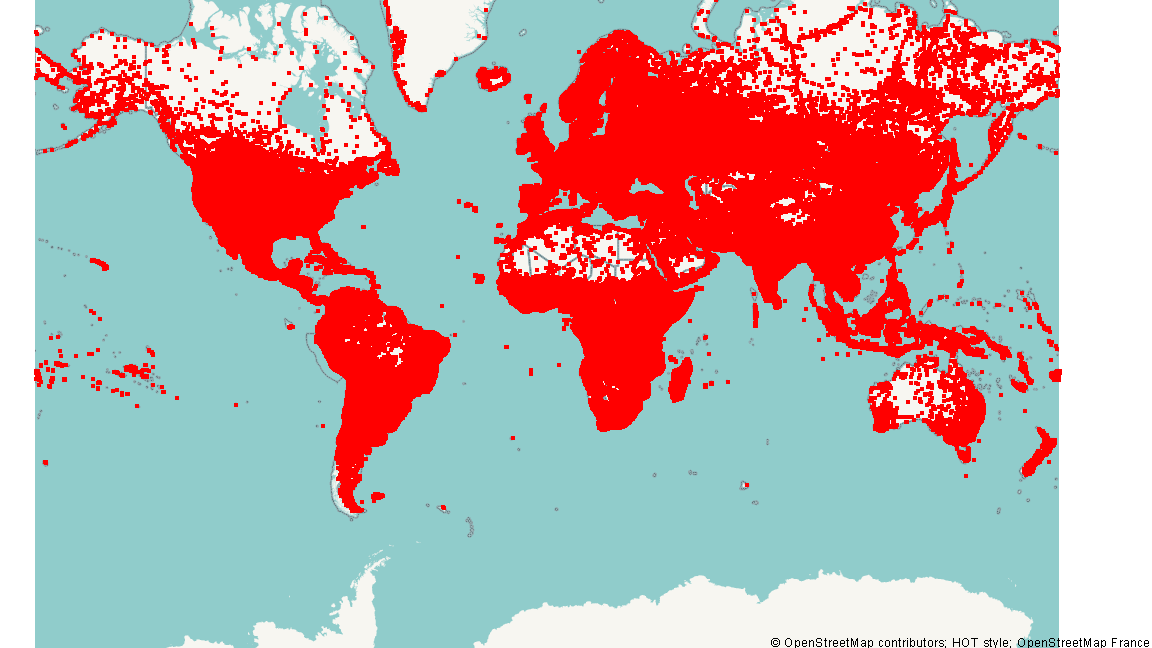

In [23]:
dataset = DataAccessObject(df)

new_map(provider="hot")
geoplotlib.dot(dataset, point_size=2)

render()

## Country aggregation

In [19]:
counts=df.groupby('Country').agg(number_of_cities=('City','size'))
display(counts.head(20))
print('Mean city records per represented country:',counts['number_of_cities'].mean())
print('This is a dataset-record average, not a complete real-world city census.')

,number_of_cities
Country,
ad,92
ae,446
af,88749
ag,183
ai,42
al,15123
am,2890
an,269
ao,19560


Mean city records per represented country: 13563.923076923076
This is a dataset-record average, not a complete real-world city census.


## Positive population dot plot

Positive population city records: 47980


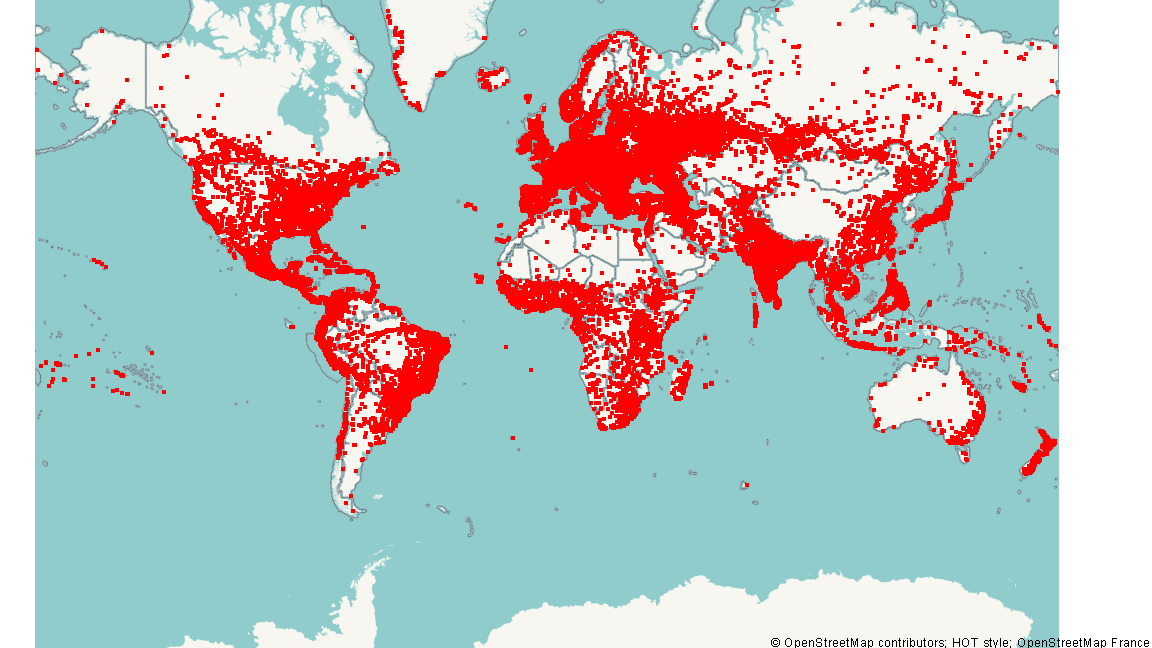

In [25]:
df_pop = df[df["Population"].gt(0)].copy()

print("Positive population city records:", len(df_pop))

data_pop = DataAccessObject(df_pop)

new_map(provider="hot")

geoplotlib.dot(
    data_pop,
    point_size=2,
)

# Display the saved map inline below this cell.
render()

## Above 100000 Voronoi

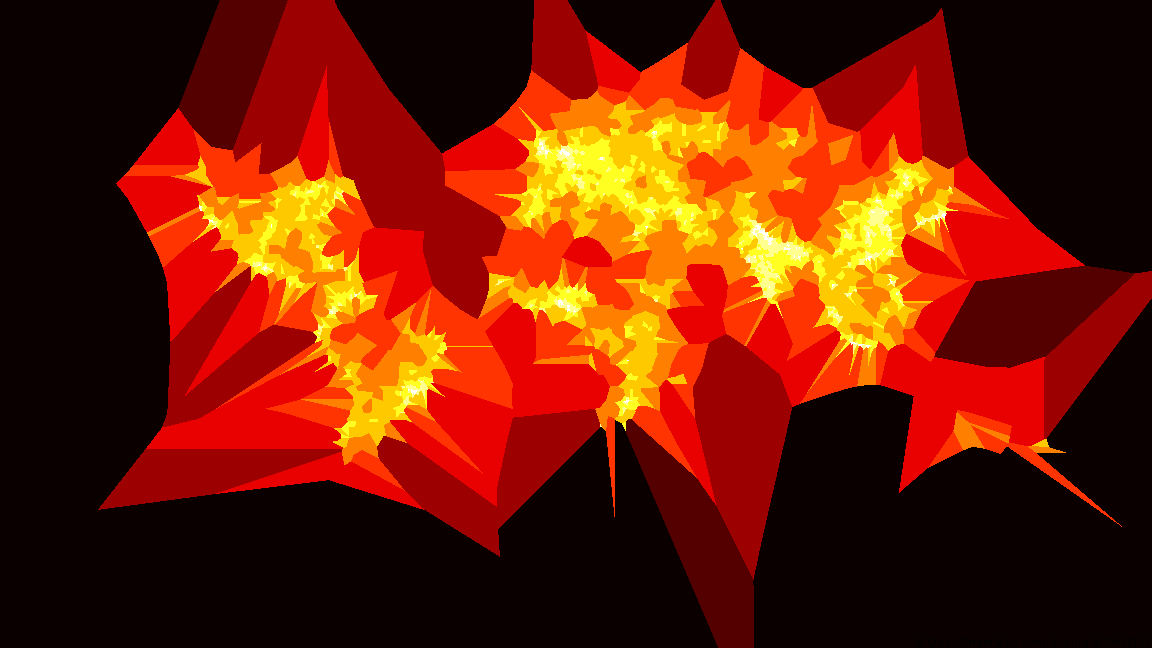

In [12]:
df_100k=df_pop[df_pop['Population'].gt(100000)].copy()
if df_100k.empty: raise ValueError('No cities above 100000.')
data_100k=DataAccessObject(df_100k)
new_map()
geoplotlib.voronoi(data_100k,cmap='hot_r',max_area=1e5,alpha=255)
render()

## Germany and Great Britain Delaunay

Cities used: 150


,Country,City,lat,lon
722416,de,aachen,50.770833,6.105278
725123,de,augsburg,48.366667,10.883333
727047,de,bergisch gladbach,50.983333,7.133333
727152,de,berlin,52.516667,13.400000
727693,de,bielefeld,52.033333,8.533333


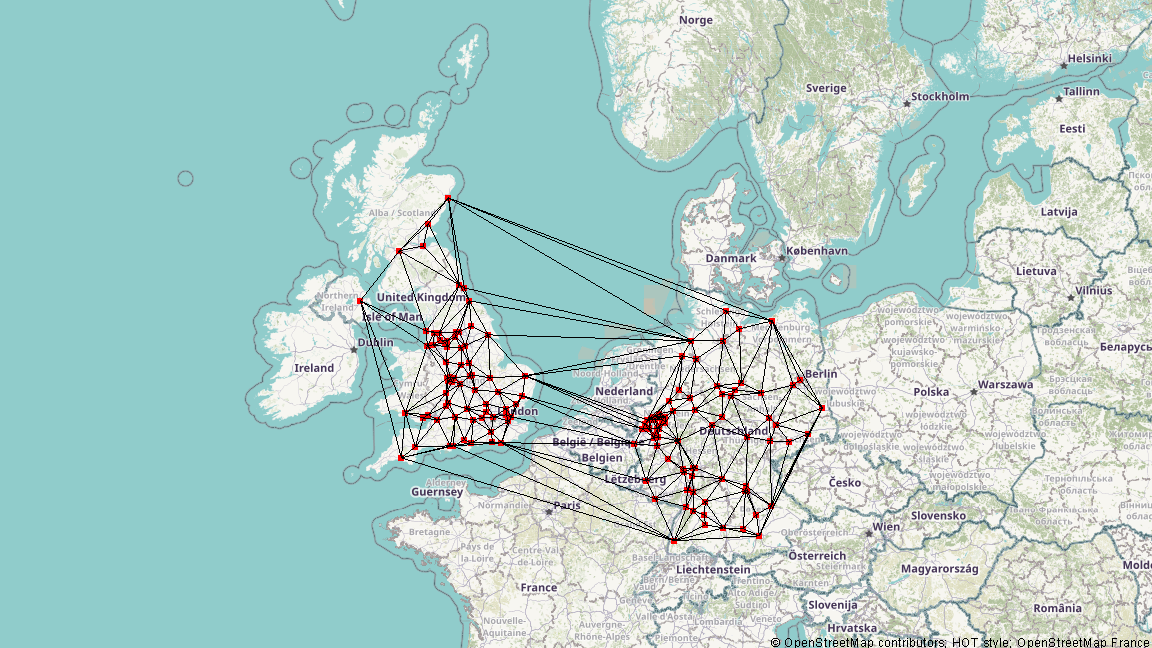

In [26]:
# Select Germany and Great Britain.
focus = df_100k[
    df_100k["Country"].isin(["de", "gb"])
].copy()

# Remove invalid and duplicate coordinates for triangulation.
focus["lat"] = pd.to_numeric(focus["lat"], errors="coerce")
focus["lon"] = pd.to_numeric(focus["lon"], errors="coerce")

focus = (
    focus.dropna(subset=["lat", "lon"])
         .drop_duplicates(subset=["lat", "lon"])
         .copy()
)

if len(focus) < 3:
    raise ValueError("Not enough distinct city coordinates.")

print("Cities used:", len(focus))
display(focus[["Country", "City", "lat", "lon"]].head())

data_focus = DataAccessObject(focus)

# Fixed viewing extent covering Great Britain and Germany.
focus_bbox = BoundingBox(
    north=60,
    west=-9,
    south=47,
    east=16,
)

# Use the HOT provider instead of CARTO Positron.
new_map(provider="hot", bbox=focus_bbox)

geoplotlib.dot(
    data_focus,
    color=[255, 0, 0],
    point_size=3,
)

geoplotlib.delaunay(
    data_focus,
    line_color=[0, 0, 0],
    line_width=1,
)

render()